# Adaptive conformal recalibration of the VaR

**Question:** When a VaR model falls behind a crisis, can a wrapper that moves the model's tail level after every hit restore the
coverage the back-tests ask for, in the stress windows of case C11 and on a generator whose true VaR is known, without making the
model's FZ0 score worse?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 02, 03 and 05 of this topic (the estimator ladder, the back-tests and consistent scoring)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- write the level update of adaptive conformal inference and say what one hit and one quiet day do to the working level;
- read what the long-run guarantee of Gibbs and Candes promises over a window of a few hundred days, and what it does not;
- replay a committed wrapped run from its hits, and measure on a generator with a known VaR how far each forecast's true hit
  probability sits from the target, before and after the wrapper;
- test the case's claim on the three stress windows from the committed hits, and say where the wrapper costs coverage.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you.
A notebook never installs anything by itself. The next cell imports what the notebook uses and prints the versions.

In [1]:
# Import the tools and print the versions they run with
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.market import conformal as cf
from riskvalidation.market import garch
from riskvalidation.validation import market as vm
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C11 back-tests a ladder of VaR and ES models on six windows of real returns: a long US equity position (the Fama-French market
factor of the Kenneth French data library), a 10-year US Treasury par bond (the Treasury's daily par curve), the euro against the
dollar (the Federal Reserve's H.10 release) and a mixed book. The forecast for day $t$ uses only the returns up to $t-1$. The equity
series is derived-only: its realised losses are withheld from the committed documents, while each model's forecasts, its hit days
and its scores are committed. Three of the windows are the stress windows of the claim: equity 2007 to 2009, equity 2020 and rates
2022. Each document also carries the wrapped runs of HS-250, GARCH-t and FHS at 1 % and 2.5 %.

In [2]:
# Read the committed documents of case C11: the six windows, each model's hits and the wrapped runs
C11 = ROOT / "data" / "derived" / "C11"
WINDOWS = ("equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "calm-2004-06", "mixed-2023")
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8"))["outputs"] for w in WINDOWS}
run = docs["equity-2007-09"]["conformal"]["hypothesis"]["run"]
GAMMA, LOW, HIGH = run["gamma"], run["level_min"], run["level_max"]
print(f"gamma {GAMMA} | band [{LOW}, {HIGH}] | stress windows: {', '.join(run['stress_windows'])}")
for w, o in docs.items():
    status = o["grid"]["realised_loss"]["status"]
    rows = len(o["conformal"]["rows"])
    print(f"{w:15s} {len(o['grid']['dates']):4d} days | realised loss: {status} | {rows} wrapped runs")


gamma 0.005 | band [0.001, 0.25] | stress windows: equity-2007-09, equity-2020, rates-2022
equity-2007-09   504 days | realised loss: withheld-derived-only | 6 wrapped runs
equity-2020      104 days | realised loss: withheld-derived-only | 6 wrapped runs
rates-2022       249 days | realised loss: included | 6 wrapped runs
fx-2008          251 days | realised loss: included | 6 wrapped runs
calm-2004-06     750 days | realised loss: withheld-derived-only | 6 wrapped runs
mixed-2023        64 days | realised loss: withheld-derived-only | 6 wrapped runs


## Method

A VaR model gives, for day $t$ and a tail level $a$, a forecast $\mathrm{VaR}_t(a)$ built from the returns before $t$. The wrapper
does not touch the model. It keeps a working level $a_t$, starting at the target $\alpha$, asks the model for its VaR at $a_t$,
and after the day moves the level (Gibbs and Candes, 2021):

$$a_{t+1} = \operatorname{clip}\big(a_t + \gamma\,(\alpha - \mathrm{err}_t),\ a_{\min},\ a_{\max}\big), \qquad
\mathrm{err}_t = \mathbb{1}\{y_t < \mathrm{VaR}_t(a_t)\}.$$

A hit lowers the level by $\gamma(1-\alpha)$, so the next VaR is deeper; a quiet day raises it by $\gamma\alpha$. The step
$\gamma = 0.005$ and the band $[0.001, 0.25]$ were fixed before any run. The engine's `market.conformal` holds the update, the
wrapper and the comparison; the next cell walks the update by hand.

In [3]:
# The level update step by step: a target of 1 %, ten quiet days, one hit, then ten quiet days again
level = 0.01
path = [level]
for hit in [False] * 10 + [True] + [False] * 10:
    level = cf.aci_update(level, hit, 0.01, GAMMA, LOW, HIGH)
    path.append(level)
print(" ".join(f"{100 * x:.3f}" for x in path))
print(f"a quiet day raises the level by {100 * GAMMA * 0.01:.4f} pp")
print(f"a hit lowers it by {100 * GAMMA * 0.99:.3f} pp")
print(f"quiet days to undo one hit: {0.99 / 0.01:.0f}")
# The bound of Gibbs and Candes on the gap between the hit rate and the target, for a run of T days
for days in (250, 504, 2500, 39800):
    print(f"T {days:6d} | largest gap between the hit rate and 1 %: {(0.99 + GAMMA) / (GAMMA * days):.4f}")


1.000 1.005 1.010 1.015 1.020 1.025 1.030 1.035 1.040 1.045 1.050 0.555 0.560 0.565 0.570 0.575 0.580 0.585 0.590 0.595 0.600 0.605
a quiet day raises the level by 0.0050 pp
a hit lowers it by 0.495 pp
quiet days to undo one hit: 99
T    250 | largest gap between the hit rate and 1 %: 0.7960
T    504 | largest gap between the hit rate and 1 %: 0.3948
T   2500 | largest gap between the hit rate and 1 %: 0.0796
T  39800 | largest gap between the hit rate and 1 %: 0.0050


At 1 % a quiet day adds 0.005 percentage points to the level and a hit takes 0.495 away, so one hit needs 99 quiet days to be
undone: the level reacts at once to a cluster of hits and relaxes slowly. The guarantee is about the long run. Gibbs and Candes
bound the gap between the hit rate and the target by $(\max(a_1, 1-a_1) + \gamma)/(\gamma T)$, which at $\gamma = 0.005$ is 0.796
over 250 days and 0.395 over the 504 days of equity 2007 to 2009: it allows any hit rate from 0 to 40 %. The bound reaches half a
percentage point only after 39,800 days, about 158 years of trading. Over a stress window the theorem says nothing, so what the
wrapper does there has to be measured.

In [4]:
# Replay the working level of GARCH-t at 1 % in equity-2007-09 from the hits of its committed wrapped VaR
eq = docs["equity-2007-09"]
row = next(r for r in eq["conformal"]["rows"] if r["model_id"] == "garch-t" and r["alpha"] == 0.01)
n = row["n_days"]
wrapped_hits = np.zeros(n, bool)
wrapped_hits[row["series"]["exceedance_days"]] = True
levels = [0.01]
for hit in wrapped_hits[:-1]:
    levels.append(cf.aci_update(levels[-1], bool(hit), 0.01, GAMMA, LOW, HIGH))
levels = np.array(levels)
gap = np.abs(levels - np.array(row["series"]["working_level"])).max()
print(f"largest gap between the replayed and the committed level: {gap:.1e}")
print(f"min {100 * levels.min():.3f} % | mean {100 * levels.mean():.3f} % | max {100 * levels.max():.3f} %")
print(f"days at the floor of the band: {int((levels <= LOW + 1e-12).sum())} | days clipped: {row['n_clipped']}")


largest gap between the replayed and the committed level: 4.7e-17
min 0.100 % | mean 0.515 % | max 1.075 %
days at the floor of the band: 3 | days clipped: 3


The update applied to the 6 committed hits of the wrapped GARCH-t reproduces the committed working level to machine precision
(the largest gap is 4.7e-17). The level fell from 1 % to the floor of the band, 0.1 %, and touched it on 3 days, the 3 days the
document reports as clipped; its mean over the window is 0.515 % and its highest value 1.075 %. The figure puts the level next to the hits.

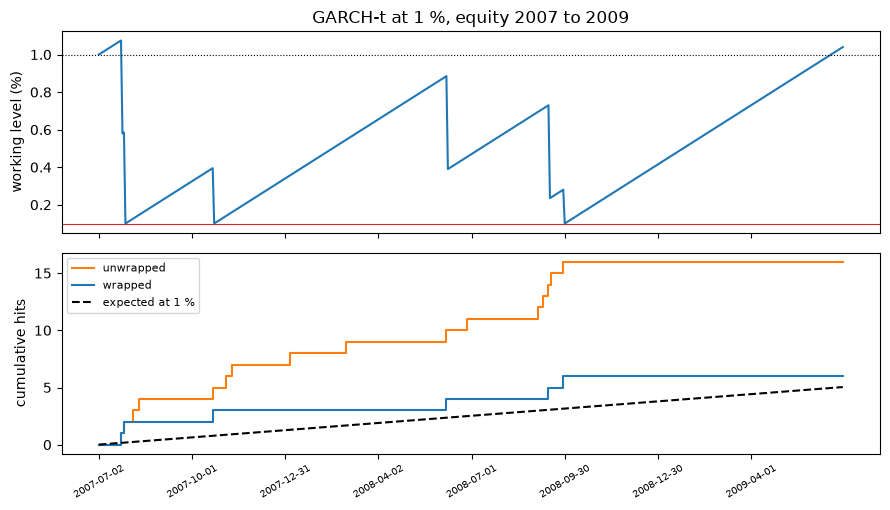

unwrapped: 16 | wrapped: 6 | expected at 1 %: 5.04


In [5]:
# Draw the working level and the cumulative hits of GARCH-t at 1 % in equity-2007-09, unwrapped and wrapped
ladder = {m["model_id"]: m for m in eq["models"]}
plain = next(b for b in ladder["garch-t"]["by_level"] if b["alpha"] == 0.01)
plain_hits = np.zeros(n, bool)
plain_hits[plain["exceedance_days"]] = True
dates = eq["grid"]["dates"]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
top.plot(100 * levels, color="tab:blue")
top.axhline(1.0, color="black", linestyle=":", linewidth=0.8)
top.axhline(100 * LOW, color="tab:red", linewidth=0.8)
top.set_ylabel("working level (%)")
top.set_title("GARCH-t at 1 %, equity 2007 to 2009")
bottom.step(range(n), np.cumsum(plain_hits), where="post", color="tab:orange", label="unwrapped")
bottom.step(range(n), np.cumsum(wrapped_hits), where="post", color="tab:blue", label="wrapped")
bottom.plot(0.01 * np.arange(1, n + 1), color="black", linestyle="--", label="expected at 1 %")
bottom.set_ylabel("cumulative hits")
ticks = list(range(0, n, 63))
bottom.set_xticks(ticks)
bottom.set_xticklabels([dates[i] for i in ticks], rotation=30, fontsize=7)
bottom.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"unwrapped: {int(plain_hits.sum())} | wrapped: {int(wrapped_hits.sum())} | "
      f"expected at 1 %: {0.01 * n:.2f}")


The top panel is the working level: it drops to the floor at the hits of late July 2007, October 2007 and the end of September
2008, drops halfway at the hit of June 2008, and climbs back by 0.005 points a day in between; after the last hit it needs until
June 2009 to return to 1 %. The bottom panel counts the hits. The model at a fixed 1 % (orange) has 16 hits in 504 days against
5.04 expected, in clusters, the largest in the summer of 2007 and in September 2008; wrapped (blue), it has 6, close to the dashed
line of the target throughout. The wrapped model asks GARCH-t for a deeper quantile while the crisis lasts, which is the whole of
the method.

## Comparison

The methods compared are each model as the ladder runs it, at a fixed level, and the same model wrapped. A real window has one path
and no known VaR, so a hit count of 6 against 16 cannot say how far each forecast was from the truth. The comparison therefore runs
the generator of the engine's study, where the true VaR of every day is known: a Student-t(5) GARCH(1,1) after a calm history of
1,000 days, then 500 days whose volatility ramps to three times, holds and decays to 1.5 times, the shape of 2007 to 2009. HS-250
rolls its 250-day window; GARCH-t is fitted once on the calm history and filtered day by day. The true probability of a hit of a
forecast is the Student-t distribution function at the forecast scaled by the true volatility, so the coverage of every day is
measured without sampling noise.

In [6]:
# The generator of the engine's study: a calm GARCH(1,1)-t history of 1,000 days, then 500 days whose volatility
# ramps to three times in 250 days, holds for 100 and decays to 1.5 times; the true VaR of every day is known
NU, HISTORY, LENGTH = 5.0, 1000, 500
SCALE = np.sqrt((NU - 2) / NU)


def crisis_path(rng):
    z = rng.standard_t(NU, HISTORY + LENGTH + 300) * SCALE
    ramp = np.interp(np.arange(LENGTH), [0, 250, 350, LENGTH - 1], [1.0, 3.0, 3.0, 1.5])
    mult = np.concatenate([np.ones(300 + HISTORY), ramp])
    s2, y, sd = 2e-6 / 0.02, np.empty(z.size), np.empty(z.size)
    for t in range(z.size):
        e = np.sqrt(s2) * z[t]
        y[t] = mult[t] * e
        sd[t] = mult[t] * np.sqrt(s2)
        s2 = 2e-6 + 0.08 * e * e + 0.90 * s2
    return y[300:], sd[300:]


# The true probability that the day's return falls below a forecast VaR
def true_level(var, sd):
    return stats.t.cdf(var / (sd * SCALE), NU)


# GARCH(1,1)-t fitted once on the calm history, then filtered day by day
def frozen_garch(y):
    fit = garch.fit_garch(y[:HISTORY], "garch", "student-t", "constant")
    return lambda t, level: garch.garch_var_es_forecast(fit, y[max(0, t - HISTORY):t], level)


The next cell draws one path of the generator, seed 20261030, and runs both models twice over its 500-day window: at a fixed
1 % and wrapped. Each run is scored on its hits, with Kupiec's test as a desk would read it, and on the true probability of a hit of
each forecast, a number only a generator with a known VaR can give.

In [7]:
# One path: HS-250 and GARCH-t, unwrapped and wrapped at 1 %, scored on the hits and against the true level
y, sd = crisis_path(np.random.default_rng(20261030))
models = {"HS-250": cf.historical_forecaster(y, 250), "GARCH-t": frozen_garch(y)}
runs = {}
for name, f in models.items():
    c = cf.aci_compare(y, f, 0.01, gamma=GAMMA, start=HISTORY)
    plain_run = cf.aci_var_es(y, f, 0.01, 0.0, HISTORY)
    runs[name] = (plain_run, c.result)
    for side, s, r in (("unwrapped", c.unwrapped, plain_run), ("wrapped", c.wrapped, c.result)):
        p = true_level(r.var, sd[HISTORY:]).mean()
        print(f"{name:8s} {side:12s} hits {s.n_hits:3d} / {s.n} | Kupiec {s.kupiec_p:.3f} | "
              f"true hit probability {100 * p:.2f} %")
    print(f"{name:8s} FZ0 change {100 * c.fz0_change:+.1f} % | days clipped {c.result.n_clipped}")


HS-250   unwrapped    hits  16 / 500 | Kupiec 0.000 | true hit probability 3.66 %
HS-250   wrapped      hits  10 / 500 | Kupiec 0.048 | true hit probability 2.27 %
HS-250   FZ0 change -6.4 % | days clipped 7
GARCH-t  unwrapped    hits   7 / 500 | Kupiec 0.397 | true hit probability 1.30 %
GARCH-t  wrapped      hits   6 / 500 | Kupiec 0.663 | true hit probability 1.10 %
GARCH-t  FZ0 change +3.0 % | days clipped 0


On this path HS-250 at a fixed 1 % has 16 hits in 500 days and fails Kupiec (p 0.000); its true probability of a hit
averages 3.66 %, more than three times the target. Wrapped, it has 10 hits, Kupiec p 0.048, and a true probability of 2.27 %:
better, still above the target, and the level reached the floor on 7 days. GARCH-t follows the volatility by construction and
is already close: 7 hits and 1.30 % unwrapped, 6 hits and 1.10 % wrapped, at a cost of 3.0 % in FZ0. The figure shows HS-250.

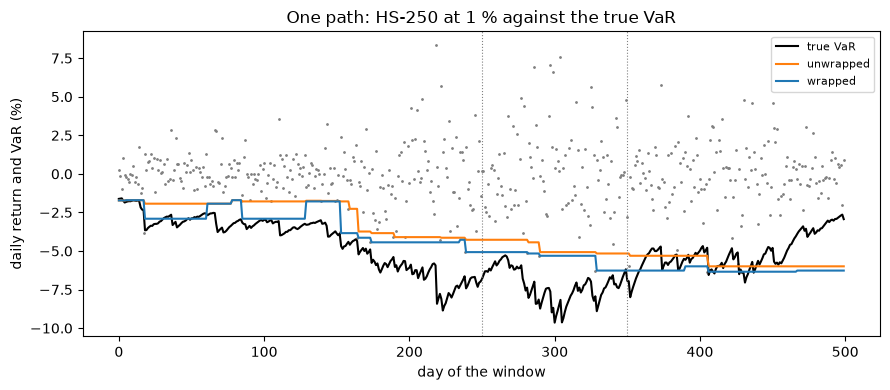

In [8]:
# Draw the window of that path: the returns, the true VaR at 1 % and HS-250's VaR unwrapped and wrapped
days = np.arange(LENGTH)
truth = sd[HISTORY:] * SCALE * stats.t.ppf(0.01, NU)
plain_run, wrapped_run = runs["HS-250"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, 100 * y[HISTORY:], ".", color="grey", markersize=2)
ax.plot(days, 100 * truth, color="black", label="true VaR")
ax.plot(days, 100 * plain_run.var, color="tab:orange", label="unwrapped")
ax.plot(days, 100 * wrapped_run.var, color="tab:blue", label="wrapped")
for edge in (250, 350):
    ax.axvline(edge, color="grey", linestyle=":", linewidth=0.8)
ax.set_xlabel("day of the window")
ax.set_ylabel("daily return and VaR (%)")
ax.set_title("One path: HS-250 at 1 % against the true VaR")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The black line is the true VaR at 1 %; it falls with the volatility in the ramp (to day 250), holds on the plateau and rises
in the decay. The orange VaR of HS-250 lags it by months, because its 250-day window keeps the calm days until they roll out. The
blue wrapped VaR drops below the orange one after the first hits, near day 20, and stays closer to the truth on the plateau. From
about day 400 both sit deeper than the truth: HS-250 because its window still holds the crisis, the wrapped VaR also because its
level recovers by only 0.005 points a day.

In [9]:
# Thirty paths of the same generator: the true probability of a hit of each forecast, by phase of the window
PHASES = ((0, 250), (250, 350), (350, 500))
study = {"HS-250": [], "GARCH-t": []}
for rep in range(30):
    y_r, sd_r = crisis_path(np.random.default_rng([20261030, rep]))
    for name, f in (("HS-250", cf.historical_forecaster(y_r, 250)), ("GARCH-t", frozen_garch(y_r))):
        pair = [cf.aci_var_es(y_r, f, 0.01, g, HISTORY) for g in (0.0, GAMMA)]
        scores = [cf.forecast_scores(y_r[HISTORY:], r.var, r.es, 0.01) for r in pair]
        probs = [true_level(r.var, sd_r[HISTORY:]) for r in pair]
        passed = [s.kupiec_p is not None and s.cc_p is not None and min(s.kupiec_p, s.cc_p) >= 0.05 for s in scores]
        change = (scores[1].fz0_mean - scores[0].fz0_mean) / abs(scores[0].fz0_mean)
        phases = [p[a:b].mean() for p in probs for a, b in PHASES]
        study[name].append([p.mean() for p in probs] + passed + [change] + phases)
for name, rows in study.items():
    x = np.array(rows, float)
    by_phase = zip(x[:, 5:8].mean(0), x[:, 8:11].mean(0))
    print(f"{name:8s} true hit probability {100 * x[:, 0].mean():.2f} % / {100 * x[:, 1].mean():.2f} % | "
          f"pass rate {x[:, 2].mean():.2f} / {x[:, 3].mean():.2f} | "
          f"FZ0 change {100 * np.median(x[:, 4]):+.1f} %")
    print(f"{'':8s} by phase: " + " | ".join(f"{100 * u:.2f} / {100 * w:.2f}" for u, w in by_phase))


HS-250   true hit probability 2.40 % / 1.37 % | pass rate 0.23 / 0.83 | FZ0 change -8.5 %
         by phase: 3.43 / 1.90 | 2.25 / 1.25 | 0.79 / 0.57
GARCH-t  true hit probability 1.73 % / 1.15 % | pass rate 0.60 / 0.97 | FZ0 change -0.2 %
         by phase: 1.78 / 1.33 | 1.90 / 1.13 | 1.55 / 0.88


Over thirty paths HS-250's true probability of a hit falls from 2.40 % to 1.37 % and its pass rate (Kupiec and conditional
coverage both at least 0.05) rises from 0.23 to 0.83, with a median FZ0 change of -8.5 % (an improvement). GARCH-t goes from 1.73 %
to 1.15 % and from 0.60 to 0.97, with a median FZ0 change of -0.2 %. The engine's study, with 100 paths, measured pass rates of
0.18 to 0.87 and 0.44 to 0.97 for the same scenario. The figure splits the window by phase.

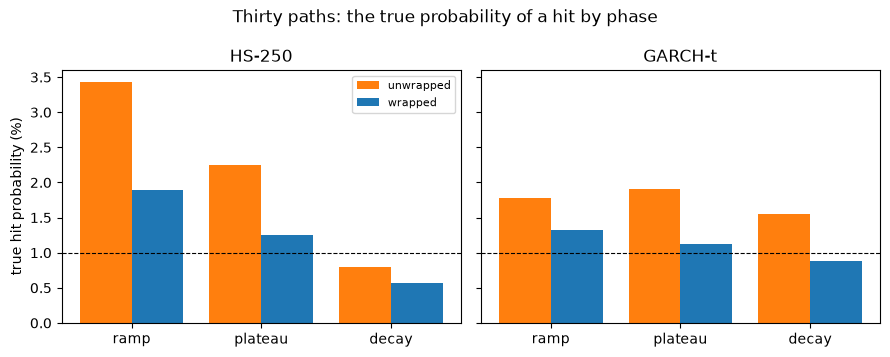

In [10]:
# Draw the mean true probability of a hit by phase, both models unwrapped and wrapped, against the 1 % target
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
x = np.arange(3)
for ax, (name, rows) in zip(axes, study.items()):
    arr = np.array(rows, float)
    ax.bar(x - 0.2, 100 * arr[:, 5:8].mean(0), 0.4, color="tab:orange", label="unwrapped")
    ax.bar(x + 0.2, 100 * arr[:, 8:11].mean(0), 0.4, color="tab:blue", label="wrapped")
    ax.axhline(1.0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(["ramp", "plateau", "decay"])
    ax.set_title(name)
axes[0].set_ylabel("true hit probability (%)")
axes[0].legend(fontsize=8)
fig.suptitle("Thirty paths: the true probability of a hit by phase")
fig.tight_layout()
plt.show()


The dashed line is the 1 % target. In the ramp HS-250 unwrapped sits at 3.43 % and wrapped at 1.90 %; on the plateau at
2.25 % and 1.25 %. In the decay both are below the target, 0.79 % and 0.57 %: the wrapper keeps a crisis level for months after
the crisis, and there it makes an already conservative model more conservative. GARCH-t, which follows the volatility, moves from
1.78 %, 1.90 % and 1.55 % to 1.33 %, 1.13 % and 0.88 %. The wrapper corrects the level the model gets wrong on average; it does
not tell the phases apart.

## Evidence

The claim, fixed in the SDD before any run: HS-250, GARCH-t and FHS, wrapped, pass the coverage tests (Kupiec and conditional
coverage, both p at least 0.05) in at least one more of the three stress windows than unwrapped, without their mean FZ0 worsening by
more than 5 %; it is refuted if the wrapped model fails the independence test in equity 2007 to 2009. The next cell recomputes the
three tests of the 18 stress runs, unwrapped and wrapped, from the committed hit days, with the engine's `validation.market`.

In [11]:
# Recompute the coverage tests of every stress run from its committed hit days, unwrapped and wrapped
def passes(days, n_days, alpha):
    flags = np.zeros(n_days, bool)
    flags[days] = True
    kupiec = vm.kupiec_pof(flags, alpha).p_value
    cc = vm.christoffersen_conditional_coverage(flags, alpha).p_value
    indep = vm.christoffersen_independence(flags, alpha).p_value
    return kupiec is not None and cc is not None and min(kupiec, cc) >= 0.05, indep


cells = {}
for w in run["stress_windows"]:
    ladder_w = {m["model_id"]: m for m in docs[w]["models"]}
    for r in docs[w]["conformal"]["rows"]:
        plain_w = next(b for b in ladder_w[r["model_id"]]["by_level"] if b["alpha"] == r["alpha"])
        before, _ = passes(plain_w["exceedance_days"], r["n_days"], r["alpha"])
        after, indep = passes(r["series"]["exceedance_days"], r["n_days"], r["alpha"])
        cell = cells.setdefault((r["model_id"], r["alpha"]), {"before": 0, "after": 0, "fz0": [], "indep": None})
        cell["before"] += before
        cell["after"] += after
        cell["fz0"].append(r["fz0_change"])
        if w == "equity-2007-09":
            cell["indep"] = indep
for (model, alpha), c in cells.items():
    print(f"{model:8s} {100 * alpha:.1f} % | stress windows passed {c['before']} / {c['after']} | "
          f"worst FZ0 change {100 * max(c['fz0']):+.1f} % | wrapped independence p in 2007-09 {c['indep']:.3f}")


hs-250   1.0 % | stress windows passed 0 / 1 | worst FZ0 change -5.8 % | wrapped independence p in 2007-09 0.483
hs-250   2.5 % | stress windows passed 0 / 2 | worst FZ0 change -3.3 % | wrapped independence p in 2007-09 0.275
garch-t  1.0 % | stress windows passed 2 / 3 | worst FZ0 change +3.0 % | wrapped independence p in 2007-09 0.703
garch-t  2.5 % | stress windows passed 1 / 3 | worst FZ0 change -0.3 % | wrapped independence p in 2007-09 0.371
fhs      1.0 % | stress windows passed 2 / 3 | worst FZ0 change +3.4 % | wrapped independence p in 2007-09 0.657
fhs      2.5 % | stress windows passed 1 / 3 | worst FZ0 change +1.5 % | wrapped independence p in 2007-09 0.371


Unwrapped, the six model-and-level cells pass 6 of their 18 stress runs; wrapped, 15. HS-250 gains a window at 1 % and two at
2.5 %, GARCH-t one and two, FHS one and two. The worst FZ0 change is +3.4 % (FHS at 1 % in equity 2020), inside the 5 % allowed.
The wrapped independence p-values in equity 2007 to 2009 run from 0.275 to 0.703, so the refutation condition does not occur. The
FZ0 changes of the equity windows are read from the documents, because their losses are withheld; rates 2022 commits its losses,
and the next cell recomputes the FZ0 change there from the committed forecasts.

In [12]:
# Recompute the FZ0 change where the realised loss is committed (rates-2022), from the committed forecasts
rates = docs["rates-2022"]
loss = np.array(rates["grid"]["realised_loss"]["loss"], float)
ladder_r = {m["model_id"]: m for m in rates["models"]}
for r in rates["conformal"]["rows"]:
    plain_r = next(b for b in ladder_r[r["model_id"]]["by_level"] if b["alpha"] == r["alpha"])
    before = cf.forecast_scores(-loss, -np.array(plain_r["var"]), -np.array(plain_r["es"]), r["alpha"])
    after = cf.forecast_scores(-loss, -np.array(r["series"]["var"]), -np.array(r["series"]["es"]), r["alpha"])
    change = (after.fz0_mean - before.fz0_mean) / abs(before.fz0_mean)
    print(f"{r['model_id']:8s} {100 * r['alpha']:.1f} % | hits {before.n_hits} / {after.n_hits} | "
          f"FZ0 {before.fz0_mean:.3f} / {after.fz0_mean:.3f} | FZ0 change {100 * change:+.1f} %")


hs-250   1.0 % | hits 8 / 4 | FZ0 -3.462 / -3.664 | FZ0 change -5.8 %
hs-250   2.5 % | hits 14 / 8 | FZ0 -3.794 / -3.919 | FZ0 change -3.3 %
garch-t  1.0 % | hits 6 / 4 | FZ0 -3.664 / -3.671 | FZ0 change -0.2 %
garch-t  2.5 % | hits 14 / 8 | FZ0 -3.906 / -3.920 | FZ0 change -0.3 %
fhs      1.0 % | hits 5 / 5 | FZ0 -3.692 / -3.659 | FZ0 change +0.9 %
fhs      2.5 % | hits 12 / 7 | FZ0 -3.932 / -3.942 | FZ0 change -0.3 %


In rates 2022 the wrapper halves the hits of HS-250 (8 to 4 at 1 %, 14 to 8 at 2.5 %) and improves its FZ0 by 5.8 % and
3.3 %; GARCH-t and FHS change by less than 1 %, and FHS at 1 %, which already passed, keeps its 5 hits and loses 0.9 % of FZ0. The
recomputed changes are the documents' own. The figure gathers the claim.

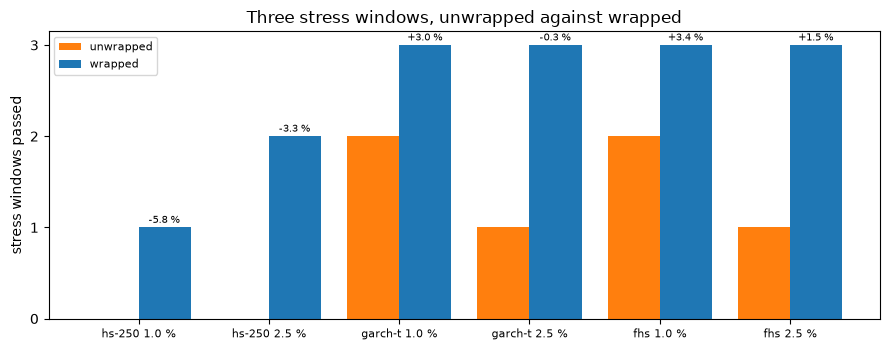

cells where the claim holds: 6 / 6 | stress-window passes gained: 9
The hypothesis holds in 6 of 6 cells (model by tail level): the wrapped models gain 9 stress-window passes in all, the worst FZ0 change in any stress window is 3.4 %, and the wrapper does not fail the independence test in equity-2007-09. It holds as a whole.


In [13]:
# Draw the stress windows each model passes at each tail level, unwrapped and wrapped, with the worst FZ0 change
labels = [f"{m} {100 * a:.1f} %" for m, a in cells]
x = np.arange(len(cells))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, [c["before"] for c in cells.values()], 0.4, color="tab:orange", label="unwrapped")
ax.bar(x + 0.2, [c["after"] for c in cells.values()], 0.4, color="tab:blue", label="wrapped")
for i, c in enumerate(cells.values()):
    ax.annotate(f"{100 * max(c['fz0']):+.1f} %", (i + 0.2, c["after"] + 0.05), ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_yticks(range(4))
ax.set_ylabel("stress windows passed")
ax.set_title("Three stress windows, unwrapped against wrapped")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
held = sum(c["after"] > c["before"] and max(c["fz0"]) <= run["fz0_tolerance"] for c in cells.values())
gained = sum(c["after"] - c["before"] for c in cells.values())
print(f"cells where the claim holds: {held} / {len(cells)} | stress-window passes gained: {gained}")
print(docs["equity-2007-09"]["conformal"]["hypothesis"]["verdict"]["en"])


Each pair of bars is a model at a tail level: orange counts the stress windows it passes as the ladder runs it, blue the
windows it passes wrapped, and the label is the worst FZ0 change across the three. Every blue bar is higher and every label is
below +5 %, so the claim holds in 6 of 6 cells and the wrapped models gain 9 stress-window passes, as the case's committed verdict
says. The wrapped HS-250 still fails equity 2020 at both levels: the wrapper narrows a crash it does not see coming, it does not
remove it. One question remains, how much the result owes to the step.

In [14]:
# The step was fixed at 0.005 before any run; how much rides on it, on the first path, HS-250 at 1 %
hs = cf.historical_forecaster(y, 250)
for g in (0.001, 0.002, 0.005, 0.01, 0.02):
    c = cf.aci_compare(y, hs, 0.01, gamma=g, start=HISTORY)
    p = true_level(c.result.var, sd[HISTORY:])
    by_phase = " / ".join(f"{100 * p[a:b].mean():.2f}" for a, b in PHASES)
    print(f"gamma {g:.3f} | hits {c.wrapped.n_hits:3d} | true hit probability {100 * p.mean():.2f} % | "
          f"by phase {by_phase} | FZ0 change {100 * c.fz0_change:+.1f} %")


gamma 0.001 | hits  13 | true hit probability 3.08 % | by phase 4.70 / 2.79 / 0.57 | FZ0 change -8.5 %
gamma 0.002 | hits  11 | true hit probability 2.83 % | by phase 4.20 / 2.79 / 0.57 | FZ0 change -8.9 %
gamma 0.005 | hits  10 | true hit probability 2.27 % | by phase 3.07 / 2.79 / 0.58 | FZ0 change -6.4 %
gamma 0.010 | hits  11 | true hit probability 2.08 % | by phase 2.60 / 2.95 / 0.62 | FZ0 change -3.0 %
gamma 0.020 | hits  12 | true hit probability 2.32 % | by phase 2.95 / 3.21 / 0.69 | FZ0 change -7.6 %


On this path no step brings HS-250 to the target. The true probability of a hit is 3.08 % at a step of 0.001, 2.83 % at
0.002, 2.27 % at the fixed 0.005, 2.08 % at 0.01 and 2.32 % at 0.02, against 3.66 % unwrapped. A larger step reacts faster in the
ramp (4.70 % at 0.001, 2.60 % at 0.01) and follows the noise of the hits more on the plateau (2.79 % up to 3.21 % at 0.02); the
decay stays near 0.6 % at every step, and FZ0 improves at every step, by 3.0 % to 8.9 %. A step of 0.01 would have done slightly
better here in coverage and worse in FZ0, and no step is best in every phase, so the result does not hinge on a tuned value.

## Results

**Answer:** Yes, in coverage and within the FZ0 tolerance. In the three stress windows of C11 the wrapper raises the passes of
HS-250, GARCH-t and FHS from 6 to 15 of 18 runs, the claim holds in 6 of 6 cells, the worst FZ0 change is +3.4 %, and the wrapped
models never fail independence in equity 2007 to 2009 (p 0.275 to 0.703). On thirty paths with a known VaR the wrapper brings
HS-250's true probability of a hit from 2.40 % to 1.37 % and GARCH-t's from 1.73 % to 1.15 %. It does so by holding a deep level
after a crisis: in the decay phase both models fall below the 1 % target, and the long-run guarantee gives no bound inside a
window of a few hundred days.

## Summary

- The wrapper keeps a working tail level that a hit lowers by $\gamma(1-\alpha)$ and a quiet day raises by $\gamma\alpha$; the
  model itself is unchanged.
- Its guarantee is on the long-run hit rate; over 504 days the bound allows any rate up to 40 %, so its effect in a window is
  measured, not promised.
- On the stress windows of C11 the wrapped models gain 9 passes of the coverage tests, with FZ0 never worse by more than 3.4 %.
- On a known truth it pulls the hit probability toward the target in the ramp and the plateau and overshoots in the decay.

## References

- Gibbs, I. and Candes, E. (2021), Adaptive conformal inference under distribution shift, Advances in Neural Information Processing Systems 34. https://arxiv.org/abs/2106.00170
- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- riskvalidation 1.1.0, `market.conformal` and its page. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/market/08_conformal-recalibration.md